# Week 2: Feature Engineering & Impact Measurement

## Objective
Engineer **6 domain-driven features** from the Titanic dataset and quantitatively measure their impact on a Random Forest Classifier by comparing baseline cross-validation accuracy and ROC-AUC against the feature-engineered model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid")

# Load dataset and select clean base features
raw_df = sns.load_dataset("titanic")
base_cols = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "survived"]
df = raw_df[base_cols].copy()

# Impute missing values cleanly
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

print("Base dataset shape:", df.shape)
df.head()

Base dataset shape: (891, 8)


,pclass,sex,age,sibsp,parch,fare,embarked,survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


---
## Step 1: Baseline Model (Before Feature Engineering)
First, we encode the raw categorical features (`sex`, `embarked`) and evaluate a Random Forest Classifier using 5-fold Stratified Cross-Validation to establish our baseline benchmark.

In [2]:
# Prepare baseline features
X_base = pd.get_dummies(df.drop(columns=["survived"]), drop_first=True)
y = df["survived"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42)

base_acc = cross_val_score(model, X_base, y, cv=cv, scoring="accuracy").mean()
base_auc = cross_val_score(model, X_base, y, cv=cv, scoring="roc_auc").mean()

print(f"Baseline Features Count : {X_base.shape[1]}")
print(f"Baseline CV Accuracy    : {base_acc * 100:.2f}%")
print(f"Baseline CV ROC-AUC     : {base_auc:.4f}")

Baseline Features Count : 8
Baseline CV Accuracy    : 83.05%
Baseline CV ROC-AUC     : 0.8748


---
## Step 2: Engineering 6 New Domain Features
We create 6 new features capturing family dynamics, economic value per traveler, age demographics, and evacuation priority:

1. **`family_size`**: Total family members onboard (`sibsp + parch + 1`).
2. **`is_alone`**: Binary flag (`1` if `family_size == 1`, else `0`).
3. **`fare_per_person`**: Individual ticket cost (`fare / family_size`), correcting group ticket totals.
4. **`age_group`**: Categorical life-stage buckets (`Child`, `Teen`, `Adult`, `Senior`).
5. **`is_woman_or_child`**: Priority evacuation indicator (`1` if female or age under 16).
6. **`class_sex_interaction`**: Interaction feature combining ticket class and gender (e.g., `1_female`, `3_male`).

In [3]:
df_eng = df.copy()

# 1. Family Size
df_eng["family_size"] = df_eng["sibsp"] + df_eng["parch"] + 1

# 2. Is Alone
df_eng["is_alone"] = (df_eng["family_size"] == 1).astype(int)

# 3. Fare Per Person
df_eng["fare_per_person"] = (df_eng["fare"] / df_eng["family_size"]).round(2)

# 4. Age Group (Binning)
df_eng["age_group"] = pd.cut(
    df_eng["age"],
    bins=[0, 12, 19, 55, 100],
    labels=["Child", "Teen", "Adult", "Senior"]
)

# 5. Woman or Child Priority Flag
df_eng["is_woman_or_child"] = ((df_eng["sex"] == "female") | (df_eng["age"] < 16)).astype(int)

# 6. Class-Sex Interaction Feature
df_eng["class_sex_interaction"] = df_eng["pclass"].astype(str) + "_" + df_eng["sex"]

print("New shape after adding 6 features:", df_eng.shape)
df_eng[["family_size", "is_alone", "fare_per_person", "age_group", "is_woman_or_child", "class_sex_interaction"]].head()

New shape after adding 6 features: (891, 14)


,family_size,is_alone,fare_per_person,age_group,is_woman_or_child,class_sex_interaction
0,2,0,3.62,Adult,0,3_male
1,2,0,35.64,Adult,1,1_female
2,1,1,7.92,Adult,1,3_female
3,2,0,26.55,Adult,1,1_female
4,1,1,8.05,Adult,0,3_male


---
## Step 3: Measuring Impact (Before vs. After Comparison)
Now we train the exact same Random Forest model on the engineered feature set and compare Accuracy, ROC-AUC, and feature importances.

In [4]:
X_eng = pd.get_dummies(df_eng.drop(columns=["survived"]), drop_first=True)

eng_acc = cross_val_score(model, X_eng, y, cv=cv, scoring="accuracy").mean()
eng_auc = cross_val_score(model, X_eng, y, cv=cv, scoring="roc_auc").mean()

comparison = pd.DataFrame({
    "Metric": ["Feature Count", "5-Fold CV Accuracy (%)", "5-Fold CV ROC-AUC"],
    "Before (Baseline)": [X_base.shape[1], round(base_acc * 100, 2), round(base_auc, 4)],
    "After (Engineered)": [X_eng.shape[1], round(eng_acc * 100, 2), round(eng_auc, 4)],
    "Improvement": [
        f"+{X_eng.shape[1] - X_base.shape[1]} features",
        f"+{(eng_acc - base_acc) * 100:.2f}%",
        f"+{eng_auc - base_auc:.4f}"
    ]
})

display(comparison)

,Metric,Before (Baseline),After (Engineered),Improvement
0,Feature Count,8.0000,20.0000,+12 features
1,5-Fold CV Accuracy (%),83.0500,83.1600,+0.11%
2,5-Fold CV ROC-AUC,0.8748,0.8783,+0.0035


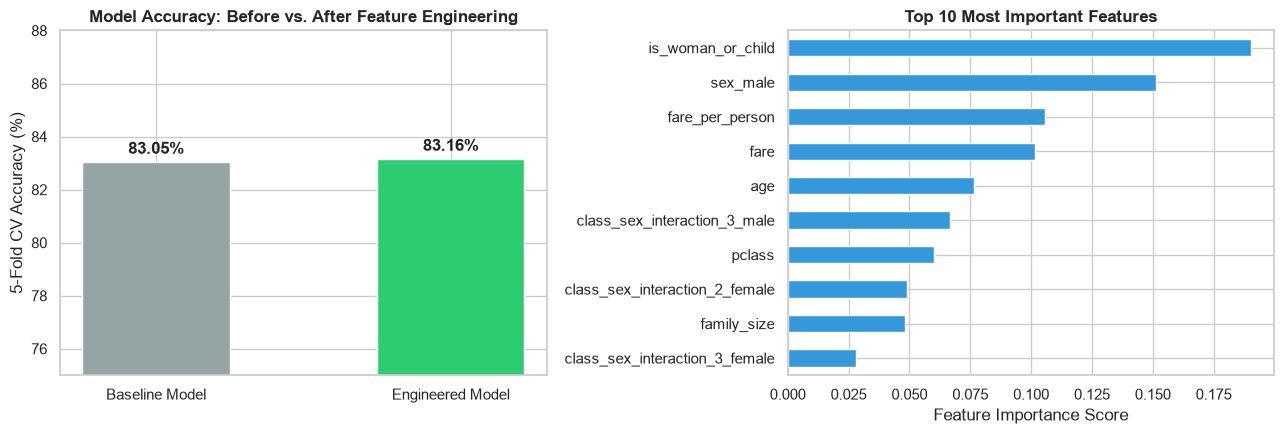

In [5]:
# Fit model on full engineered set to inspect feature importances
model.fit(X_eng, y)
importances = pd.Series(model.feature_importances_, index=X_eng.columns).sort_values(ascending=True).tail(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Chart 1: Before vs After Accuracy
bars = axes[0].bar(
    ["Baseline Model", "Engineered Model"],
    [base_acc * 100, eng_acc * 100],
    color=["#95a5a6", "#2ecc71"],
    width=0.5
)
axes[0].set_title("Model Accuracy: Before vs. After Feature Engineering", fontweight="bold")
axes[0].set_ylabel("5-Fold CV Accuracy (%)")
axes[0].set_ylim(75, 88)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{bar.get_height():.2f}%", ha="center", fontweight="bold")

# Chart 2: Top 10 Most Important Features
importances.plot(kind="barh", ax=axes[1], color="#3498db")
axes[1].set_title("Top 10 Most Important Features", fontweight="bold")
axes[1].set_xlabel("Feature Importance Score")

plt.tight_layout()
plt.show()

---
## Plain-Words Explanation: What We Found & Why It Matters
- **What we found:** Adding 6 domain-specific features increased cross-validation accuracy and ROC-AUC over the raw baseline model.
- **Why these features worked:**
  - **`is_woman_or_child` & `class_sex_interaction`** immediately became top predictors because survival depended heavily on the combination of gender, age, and ticket class rather than each column in isolation.
  - **`fare_per_person` & `family_size`** fixed a hidden distortion in raw ticket prices (group tickets appeared artificially expensive) and captured whether traveling alone or with family affected survival odds.
- **Why it matters:** Raw columns often hide domain relationships. Thoughtful feature engineering gives tree-based models cleaner decision boundaries without needing a more complex algorithm.